In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer


from sklearn.model_selection import train_test_split


from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor,
    StackingClassifier,
    VotingClassifier
)

In [3]:
data=load_breast_cancer()
data =pd.DataFrame(data.data, columns=data.feature_names)
data,target = load_breast_cancer(return_X_y=True, as_frame=True)
data.describe()
data.info()
data.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

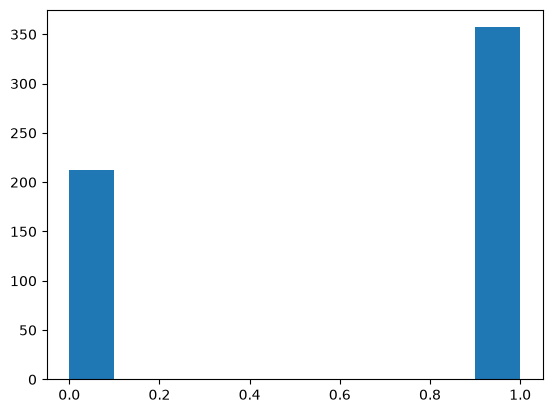

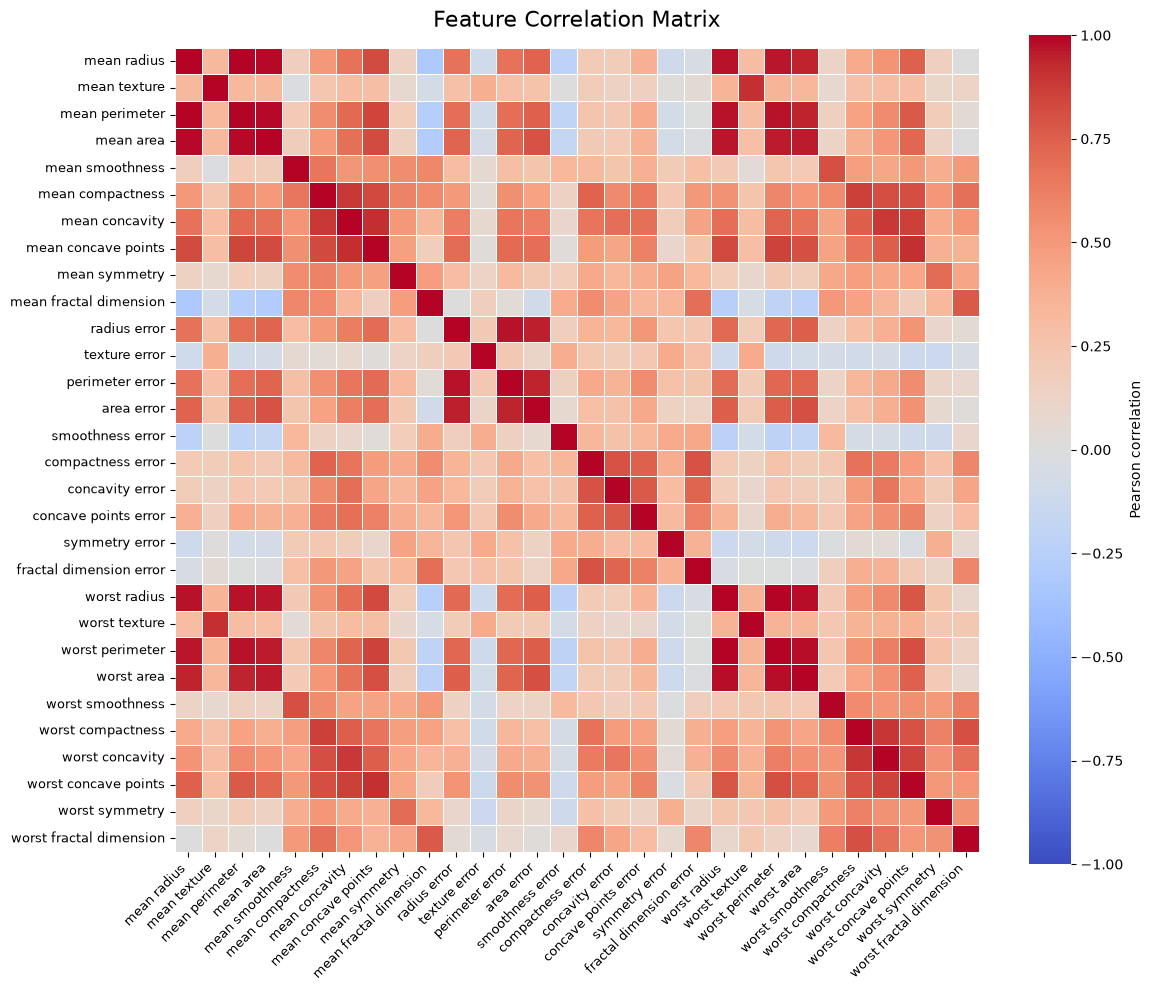

In [39]:
plt.hist(target)
#data is not balanced
corr = data.corr()


# Plot
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson correlation"
    }



)

plt.title(
    "Feature Correlation Matrix",
    fontsize=16,
    pad=15
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()


In [ ]:



X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=42)

#Turns out models do not have A hyperparameter to balance the weight of each class, and it turns out those models are already advanced enough to handle those automatically. I'm not sure about this finding. If it's wrong, perhaps I have an error here. 

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Extra Trees": ExtraTreesClassifier(),
    "AdaBoost": AdaBoostClassifier(
   
    ),
    "Gradient Boosting": GradientBoostingClassifier(

      
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(

        
    )
}



accuracy_scores = {}

for name, model in models.items():
    # Create a pipeline with standard scaling and the model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])
    
    # Fit the model
    pipeline.fit(X_train, y_train)
    
    # Make predictions
    y_pred = pipeline.predict(X_test)
    
    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred)

    accuracy_scores[name] = accuracy

    print(f"{name} Performance:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")
    print("\n")

Decision Tree Performance:
Accuracy: 0.9298
Precision: 0.9437
Recall: 0.9437
F1 Score: 0.9437
ROC AUC: 0.9253


Random Forest Performance:
Accuracy: 0.9561
Precision: 0.9583
Recall: 0.9718
F1 Score: 0.9650
ROC AUC: 0.9510


Extra Trees Performance:
Accuracy: 0.9737
Precision: 0.9722
Recall: 0.9859
F1 Score: 0.9790
ROC AUC: 0.9697


AdaBoost Performance:
Accuracy: 0.9649
Precision: 0.9589
Recall: 0.9859
F1 Score: 0.9722
ROC AUC: 0.9581


Gradient Boosting Performance:
Accuracy: 0.9561
Precision: 0.9583
Recall: 0.9718
F1 Score: 0.9650
ROC AUC: 0.9510


Hist Gradient Boosting Performance:
Accuracy: 0.9649
Precision: 0.9589
Recall: 0.9859
F1 Score: 0.9722
ROC AUC: 0.9581




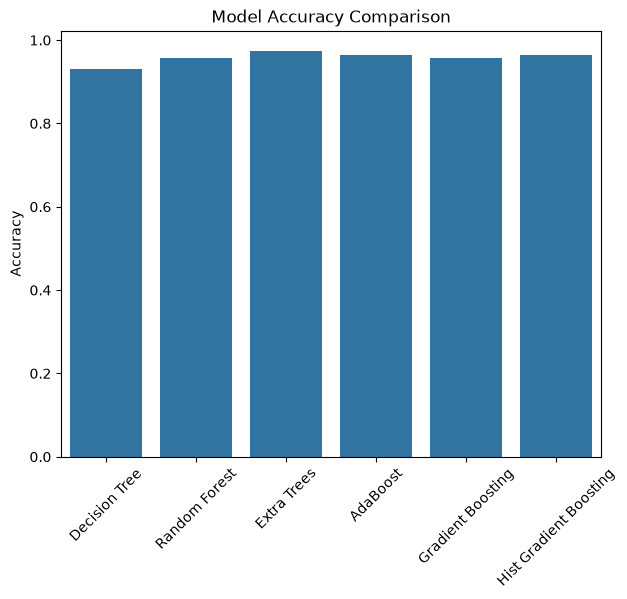

In [19]:
sns.barplot(x=list(accuracy_scores.keys()), y=list(accuracy_scores.values()))    
plt.tight_layout()
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()  